In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sea
import statsmodels.api as sm
import scipy.stats as stats
from scipy.stats import contingency
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings("ignore")

### Datenaufbereitung

Lade den Datensatz über die verfügbaren Apps im Google Play Store (googleplaystore.csv).

Überprüfe die Datenqualität anhand der Merkmale *Type* und *Price*. Gibt es Apps, die im Merkmal *Type* eine Merkmalsausprägung *Free* haben, aber einen Preis ungleich Null? Ebenso soll überprüft werden, ob es Apps mit *Price = 0* gibt, deren *Type* von *Free* abweicht. Einträge, die diese Kriterien verletzen, sollen aus dem Datensatz entfernt werden.

Überprüfe abschließend, ob Duplikate in den Einträgen existieren, und entferne diese gegebenenfalls.

#### Lösung

In [2]:
# laden des Datensatzes und Darstellung seiner wesentlichen Eigenschaften
google = pd.read_csv('../../Datasets/googleplaystore/googleplaystore.csv')
display(google.head(3))
display(google.info())

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


None

In [3]:
# Gibt es Apps, die im Merkmal *Type* eine Merkmalsausprägung *Free* haben, aber einen Preis ungleich Null?
google_free = google[google['Type'] == 'Free']
google_free.value_counts('Price')

# Alle Apps mit Type==Free sind tatsächlich kostenlos (Price==0)

Price
0    10039
Name: count, dtype: int64

In [4]:
# Apps mit *Price = 0* gibt, deren *Type* von *Free* abweicht
google_freeofcharge = google[google['Type'] != 'Free']
display(google_freeofcharge.value_counts('Price'))

Price
$0.99       148
$2.99       129
$1.99        73
$4.99        72
$3.99        63
           ... 
$5.00         1
$74.99        1
$89.99        1
0             1
Everyone      1
Name: count, Length: 93, dtype: int64

**Zwei Probleme:**
- Haben alle nicht gezeigten Werte einen Wert > $0.00?
- Was ist mit Eintrag 'Everyone'?

In [5]:
# Eintrag "Everyone"
display(google[google['Price'] == 'Everyone'])

# es scheint ein Fehler in den Daten vorzuliegen (falsche Spaltenzuordnung)
# Datensatz wird entfernt
google = google.drop(index=10472)

# check
display(google[google['Price'] == 'Everyone'])

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver


In [6]:
# Wiederholen der vorherigen Untersuchung
google_freeofcharge = google[google['Type'] != 'Free']
display(google_freeofcharge.value_counts('Price').sort_index()) # diesmal mit expliziter Sortierung der Indizes

# Eintrag mit Null
display(google_freeofcharge[google_freeofcharge['Price'] == '0'])

# hier fehlt die Angabe des Typs: kann im Datensatz verbleiben

Price
$0.99     148
$1.00       3
$1.04       1
$1.20       1
$1.26       1
         ... 
$8.99       5
$89.99      1
$9.00       2
$9.99      21
0           1
Name: count, Length: 92, dtype: int64

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
9148,Command & Conquer: Rivals,FAMILY,NaN,0,Varies with device,0,NaN,0,Everyone 10+,Strategy,"June 28, 2018",Varies with device,Varies with device


In [7]:
# Entfernung von Duplikaten mittels *drop_duplicates*
google = google.drop_duplicates(keep='first')
display(google.info())

# Reduktion der Einträge (Beobachtungen) von 10841 auf 10357

<class 'pandas.core.frame.DataFrame'>
Index: 10357 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10357 non-null  object 
 1   Category        10357 non-null  object 
 2   Rating          8892 non-null   float64
 3   Reviews         10357 non-null  object 
 4   Size            10357 non-null  object 
 5   Installs        10357 non-null  object 
 6   Type            10356 non-null  object 
 7   Price           10357 non-null  object 
 8   Content Rating  10357 non-null  object 
 9   Genres          10357 non-null  object 
 10  Last Updated    10357 non-null  object 
 11  Current Ver     10349 non-null  object 
 12  Android Ver     10355 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


None

### Datenuntersuchung

Gib folgende Kennzahlen und Eigenschaften des Datensatzes an:  
- Wie viele Einträge existieren?  
- Auf welchen Skalen sind die unterschiedlichen Merkmale definiert?  
- Welchen Modus haben die Merkmale *Category*, *Content Rating* und *Genres*?  

Stelle zusätzlich folgende Grafiken dar:  
- für *Category*: absolute Häufigkeit  
- für *Content Rating*: relative Häufigkeit  
- für *Genres*: absolute Häufigkeit der Top 20, sortiert nach Anzahl  

Wie viele Merkmalsausprägungen existieren für *Genres*?

#### Lösung

**Antwort**

Es gibt 10357 Einträge und 13 Merkmale. Die Merkmale sind folgenden Skalen zugeordnet:
- *Nominal*: App, Category, Type und Genres
- *Ordinal*: Installs, Content Rating, Current Ver und Android Ver
- *Intervallskala*: Rating und Last Updated
- *Verhältnisskala*: Price, Reviews und Size

Anmerkung: *Rating* kann auch der Ordinalskala zugeordnet werden. Ohne weitere Informationen zum Datensatz ist dies etwas schwierig. Meine Einordnung basiert darauf, dass hier ein Rating im Floatformat (anstatt einer Integerdarstellung) verwendet wird.

In [8]:
# modus der angegeben Merkmale
for col in ['Category', 'Content Rating', 'Genres']:
    print(col)
    print('Modus: {}\n'.format(google[col].mode().values))

Category
Modus: ['FAMILY']

Content Rating
Modus: ['Everyone']

Genres
Modus: ['Tools']



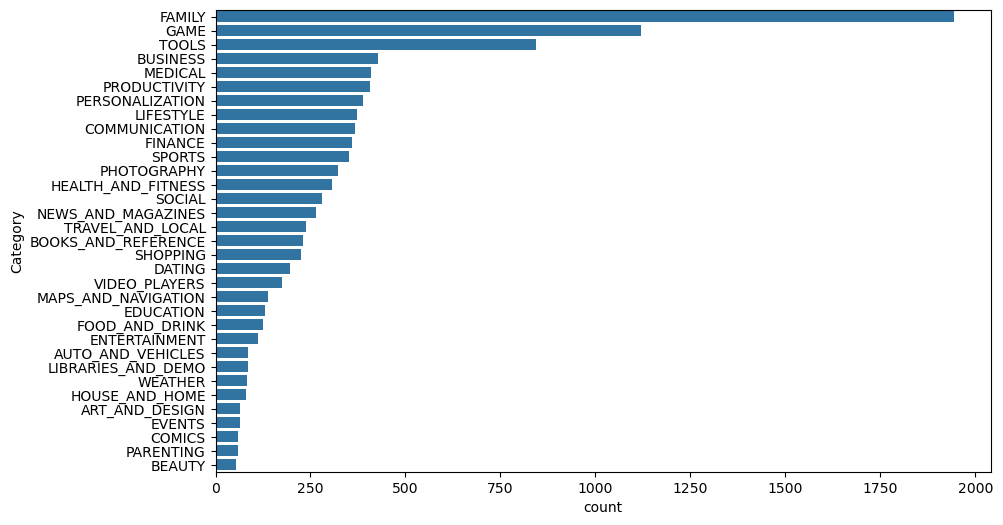

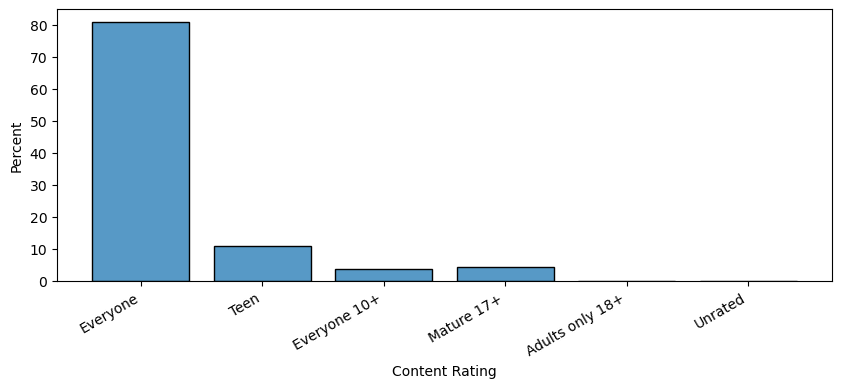

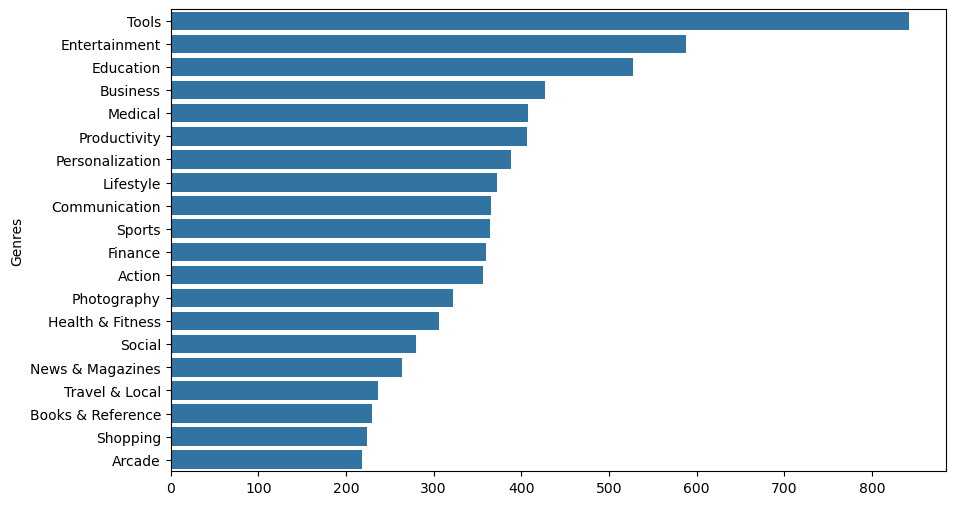

Anzahl Ausprägungen für Genre: 119


In [9]:
# Grafiken
fig, ax = plt.subplots(1,1,figsize=(10,6))
cax = ax
# sortieren der Antworten durch *order* 
sea.countplot(data=google, y='Category', ax=cax, order=google.value_counts('Category').index)
plt.show()

fig, ax = plt.subplots(1,1,figsize=(10,4))
cax = ax
sea.histplot(data=google, x='Content Rating', stat='percent', discrete=True, shrink=0.8, ax=cax)
fig.autofmt_xdate()
plt.show()

counts = google.value_counts('Genres')
fig, ax = plt.subplots(1,1,figsize=(10,6))
cax = ax
sea.barplot(y=counts.index[:20], x=counts.values[:20], ax =cax)
plt.show()

print('Anzahl Ausprägungen für Genre: {0:d}'.format(len(counts)))
# in allen Grafiken lassen sich die Ergebnisse für die gefundenen Modi entsprechend bestätigen

### Zusammenhang Qualitative Merkmale

Erstelle die Kreuztabelle für die Merkmale *Content Rating* und *Type*. Berechne damit die folgenden bedingten Häufigkeiten:

- P(Paid | Everyone)  
- P(Mature | Free)  
- Die Wahrscheinlichkeit, dass eine App mit Content Rating *Teen* kostenlos ist.  

Bewerte anschließend die statistische Abhängigkeit der beiden Merkmale basierend auf dem korrigierten Kontingenzkoeffizienten.  


#### Lösung

In [10]:
# erstellen der Kreuztabelle mit den Randhäufigkeiten
ktab = pd.crosstab(google['Type'], google['Content Rating'], margins=True, margins_name='Randhäufigkeit')
display(ktab)

# bedingte Häufigkeiten
print('P(Paid | Everyone): {0:.4f}'.format(662/8382))
print('P(Mature | Free): {0:.4f}'.format(428/9591))
print('P(Free | Teen): {0:.4f}'.format(1094/1146))

Content Rating,Adults only 18+,Everyone,Everyone 10+,Mature 17+,Teen,Unrated,Randhäufigkeit
Type,,,,,,,
Free,3,7720,344,428,1094,2,9591
Paid,0,662,32,19,52,0,765
Randhäufigkeit,3,8382,376,447,1146,2,10356


P(Paid | Everyone): 0.0790
P(Mature | Free): 0.0446
P(Free | Teen): 0.9546


In [11]:
# Bestimmung des statistischen Zusammenhangs
ktab = pd.crosstab(google['Type'], google['Content Rating'], margins=False)
nExpr = min(ktab.shape) # minimale Anzahl an Ausprägungen bei den beiden Merkmalen
pearson = contingency.association(ktab, method='pearson')
print('mit association-Methode, Pearson: {0:.4f}'.format(pearson))
print('mit association-Methode, Pearson korrigiert: {0:.4f} (max. 1)'.format(pearson*np.sqrt(nExpr/(nExpr-1))))
# die beiden Merkmale sind nur leicht abhängig (bzw. fast vollkommen unabhängig)

mit association-Methode, Pearson: 0.0484
mit association-Methode, Pearson korrigiert: 0.0685 (max. 1)


### Quantitative Merkmale

Lade den Datensatz *Advertising.csv* ein.

Der Datensatz hat 4 Merkmale und 200 Beobachtungen. Die Merkmale sind:
- *TV* - Werbebudget in Geldeinheiten [GE] für Spots im TV
- *radio* - Werbebudget in GE für Ansagen im Radio
- *newspaper* - Werbebudget in GE für Announcen in Zeitungen
- *sales* - Anzahl verkaufter Produkte [in Tsd.].

Fragestellungen:  
- Stelle für das Merkmal *TV* einen kumulativen Häufigkeitsplot dar. Welches minimale Budget haben die 30% Kampagnen mit dem höchsten TV-Budget?  
- Stelle für das Merkmal *newspaper* einen Boxplot dar. Wie viele Ausreißer existieren?

Gib zusätzlich für alle Merkmale jeweils den Median, den Interquartilsabstand, den arithmetischen Mittelwert und die Standardabweichung an.  

#### Lösung

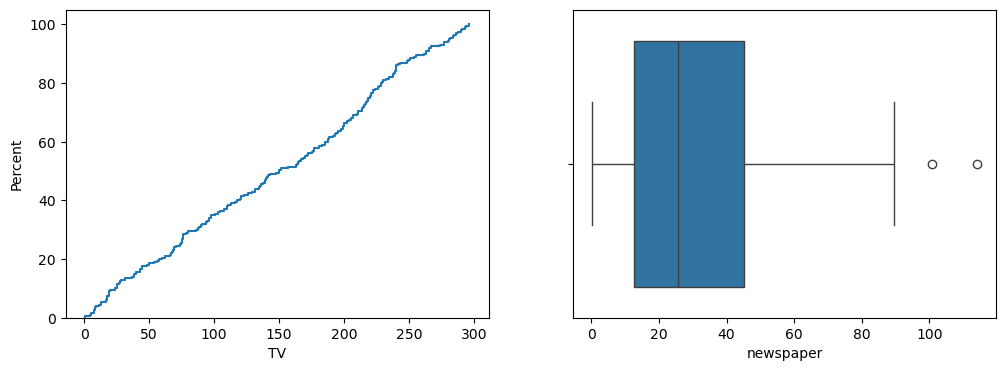

70%-Quantil von TV (minimales Budget der 30% der Kampagnen mit dem höchsten TV-Budget): 210.7300
Ausreißer


16     114.0
101    100.9
Name: newspaper, dtype: float64

In [12]:
data = pd.read_csv('../../Datasets/Advertising.csv', index_col=0)

# Grafiken
fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(12,4))
# kumulativer Häufigkeitsplot
cax = axs[0]
sea.ecdfplot(data=data, x='TV', ax=cax, stat='percent')
# boxplot
cax = axs[1]
sea.boxplot(data=data, x='newspaper', ax=cax)
plt.show()

# Antworten zu den Fragen
print('70%-Quantil von TV (minimales Budget der 30% der Kampagnen mit dem höchsten TV-Budget): {0:.4f}'.format(np.quantile(data['TV'], 0.7)))
# Bestimmung von unteren und oberen Quartil für newspaper
quarts = np.quantile(data['newspaper'], [0.25, 0.75])
outlier_bound = quarts[1] + 1.5*(quarts[1] - quarts[0])
print('Ausreißer')
display(data['newspaper'][data['newspaper'] > outlier_bound])

In [13]:
# Kennzahlen der Merkmale
tmp = data.describe()
report = pd.DataFrame(index = data.columns, columns = ['mean', 'std', 'median', 'iqr'])
for col in data.columns:
    report.loc[col] = [tmp.loc['mean',col], tmp.loc['std', col], tmp.loc['50%', col], tmp.loc['75%', col]-tmp.loc['25%', col]] 

display(report)

,mean,std,median,iqr
TV,147.0425,85.854236,149.75,144.45
radio,23.264,14.846809,22.9,26.55
newspaper,30.554,21.778621,25.75,32.35
sales,14.0225,5.217457,12.9,7.025


### Zusammenhänge quantitativer Merkmale

Stelle einen pairplot für den Datensatz dar und bestimme die Korrelationsmatrix.

Berechne die Lineare Regression für *sales* basierend auf *TV* und beantworte folgende Fragen:
- Wie lautet das Modell der Linearen Regression?
- Sind die Koeffizienten signifikant?
- Welche Aussagen über die Residuen lassen ableiten?
- Welche Aussage lässt sich aus dem Bestimmtsmaß ableiten?  
- Würdest du das Modell in der Praxis benutzen?

Stelle zusätzlich Grafiken dar, um das Ergebnis und die Qualität der Linearen Regression zu visualisieren.


Bestimme danach die multiple lineare Regression für *sales* bei Benutzung der aller Merkmale.

Beantworte folgende Fragen:

- Ist die multiple lineare Regression *besser* als die einfache lineare Regression?
- Haben alle 3 Merkmale einen Einfluss auf das Ergebnis?

Stelle auch für diesen Fall Grafiken dar, um das Ergebnis und die Qualität zu visualisieren. 

#### Lösung

Korrelationen


,TV,radio,newspaper,sales
TV,1.000000,0.054809,0.056648,0.782224
radio,0.054809,1.000000,0.354104,0.576223
newspaper,0.056648,0.354104,1.000000,0.228299
sales,0.782224,0.576223,0.228299,1.000000


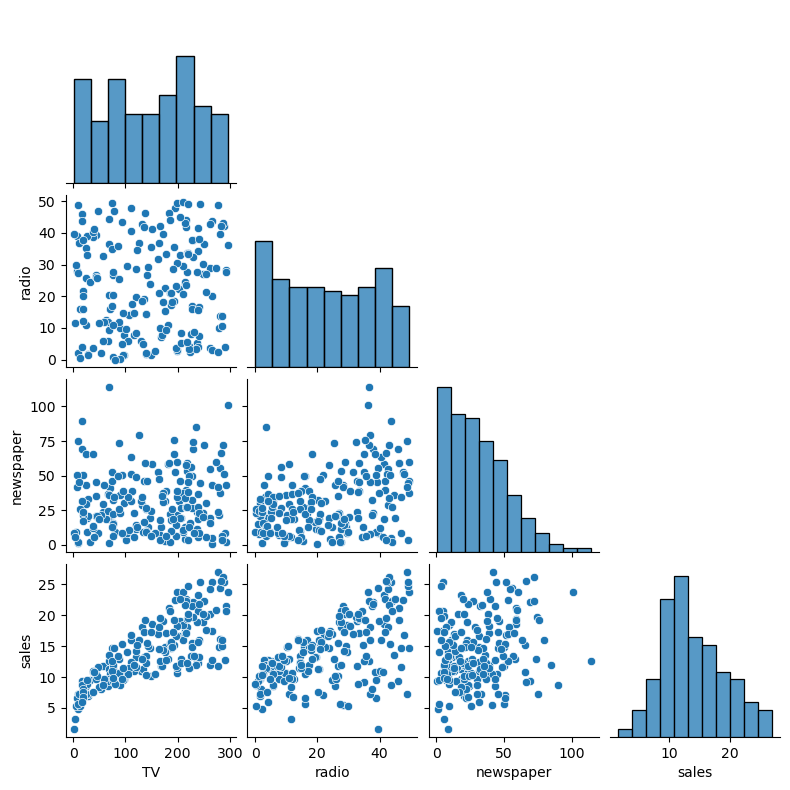

In [14]:
print('Korrelationen')
print('=============')
display(data.corr(method='pearson'))

sea.pairplot(data=data, diag_kind='hist', height=2, corner=True)
plt.show()

Model: 7.0515 + 0.0479*TV
Konfidenzintervalle:


,0,1
const,5.987755,8.115146
TV,0.041749,0.054006


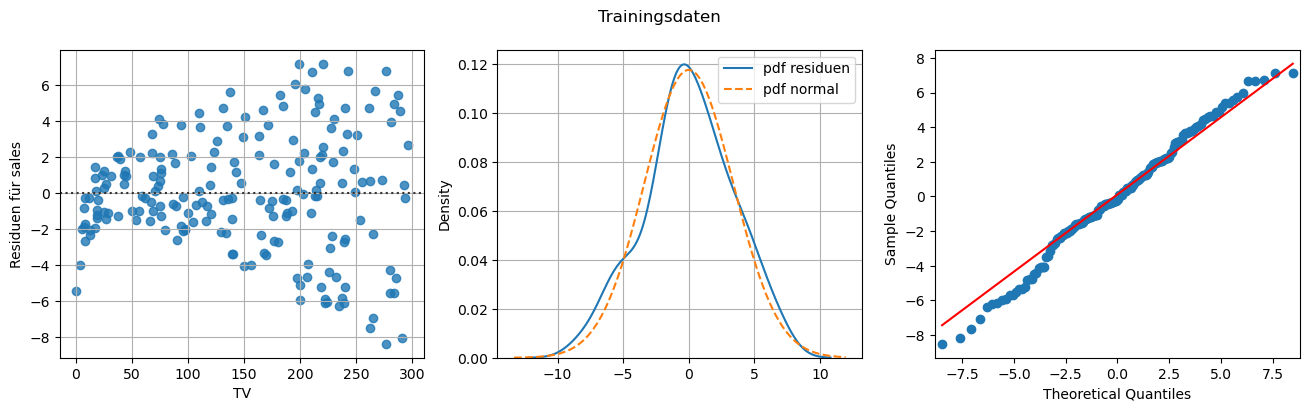

R^2: 0.6011
R^2 (Test): 0.6483



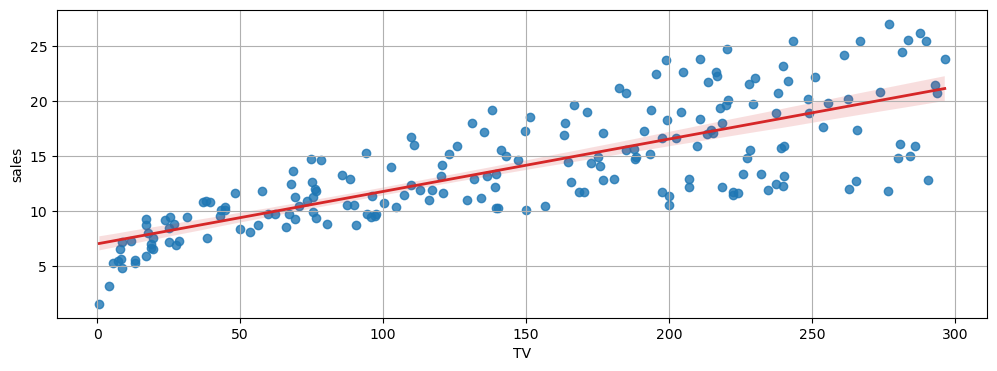

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  sales   R-squared:                       0.601
Model:                            OLS   Adj. R-squared:                  0.599
Method:                 Least Squares   F-statistic:                     238.1
Date:                Sun, 09 Nov 2025   Prob (F-statistic):           2.39e-33
Time:                        17:33:32   Log-Likelihood:                -421.24
No. Observations:                 160   AIC:                             846.5
Df Residuals:                     158   BIC:                             852.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.0515      0.539     13.093      0.000       5.988       8.115
TV             0.0479      0.003     15.430      0.000       0.042       0.054
==============================================================================
Omnibus:                        1.104   Durbin-Watson:                   2.006
Prob(Omnibus):                  0.576   Jarque-Bera (JB):                1.200
Skew:                          -0.152   Prob(JB):                        0.549
Kurtosis:                       2.704   Cond. No.                         349.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [15]:
col = 'TV'
target = 'sales'

# train-test Aufteilung
x_train, x_test, y_train, y_test = train_test_split(data[col], data[target], train_size=0.8, random_state=123456)

# lineare regression tv und sales
X = sm.add_constant(x_train, prepend=True)
mod = sm.OLS(y_train, X)
res = mod.fit()
print('Model: {0:.4f} + {1:.4f}*TV'.format(res.params['const'], res.params['TV']))
print('Konfidenzintervalle:')
print('====================')
display(res.conf_int())
pred = res.predict(sm.add_constant(x_test, prepend=True))

fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(16,4))
cax = axs[0]
sea.residplot(data=data,  x='TV', y='sales', ax=cax)
cax.grid()  
cax.set_ylabel('Residuen für sales')

cax = axs[1]
rv = stats.norm(loc=0, scale=np.std(res.resid, ddof=2))
sea.kdeplot(res.resid, ax=cax, label='pdf residuen')
xmin, xmax = cax.get_xlim()
xx = np.linspace(xmin, xmax, 101)
sea.lineplot(x=xx, y=rv.pdf(xx), linestyle='--', label='pdf normal', ax=cax)
cax.grid()

cax = axs[2]
rv = stats.norm(loc=0, scale=np.std(res.resid, ddof=2))
sm.qqplot(res.resid, rv, line='q', ax=cax)

fig.suptitle('Trainingsdaten')
plt.show()

print('R^2: {0:.4f}'.format(res.rsquared))
print('R^2 (Test): {0:.4f}\n'.format(r2_score(y_test, pred)))

fig, ax = plt.subplots(1,1,figsize=(12,4))
sea.regplot(data = data, x='TV', y='sales', ax=ax, fit_reg=True, line_kws={'linewidth':2, 'color':'tab:red'})
ax.grid()
plt.show()

display(res.summary())

**Antworten**

- Wie lautet das Modell der Linearen Regression? - $7.0515 + 0.0479 \cdot \mathrm{TV}$
- Sind die Koeffizienten signifikant? - *ja*
- Welche Aussagen über die Residuen lassen ableiten?  - *sie sind annährend normalverteilt*
- Welche Aussage lässt sich aus dem Bestimmtsmaß ableiten? - *ca. 60% Varianz lässt sich erklären*  
- Würdest du das Modell in der Praxis benutzen? - *eher nicht, aufgrund des Bestimmtheitsmaßes*


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  sales   R-squared:                       0.898
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     458.4
Date:                Sun, 09 Nov 2025   Prob (F-statistic):           4.04e-77
Time:                        17:33:32   Log-Likelihood:                -312.05
No. Observations:                 160   AIC:                             632.1
Df Residuals:                     156   BIC:                             644.4
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.8685      0.354      8.115      0.000       2.170       3.567
TV             0.0457      0.002     28.804      0.000       0.043       0.049
radio          0.1939      0.010     19.966      0.000       0.175       0.213
newspaper     -0.0020      0.007     -0.297      0.766      -0.015       0.011
==============================================================================
Omnibus:                       56.456   Durbin-Watson:                   1.951
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              163.903
Skew:                          -1.411   Prob(JB):                     2.56e-36
Kurtosis:                       7.077   Cond. No.                         460.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

R^2: 0.8962
R^2 (Test): 0.8828



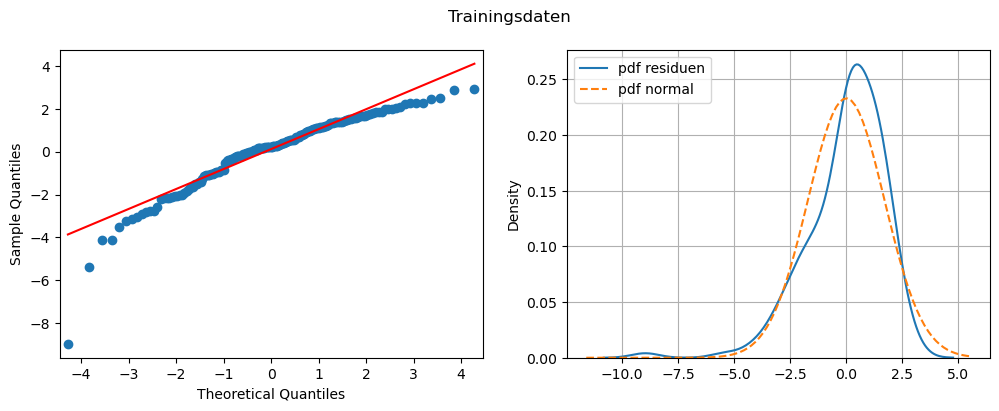

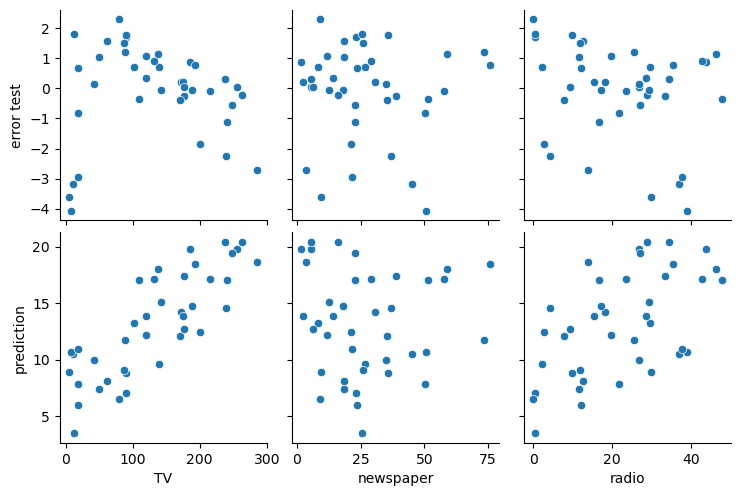

In [16]:
cols = ['TV','radio','newspaper']
target = 'sales'

# train-test Aufteilung
x_train, x_test, y_train, y_test = train_test_split(data[cols], data[target], train_size=0.8, random_state=123456)

# alle merkmale
X = sm.add_constant(x_train, prepend=True)
mod = sm.OLS(y_train, X)
res = mod.fit()
pred = res.predict(sm.add_constant(x_test, prepend=True))
display(res.summary())

print('R^2: {0:.4f}'.format(res.rsquared_adj))
print('R^2 (Test): {0:.4f}\n'.format(1 - (y_train.shape[0] - 1)/(y_train.shape[0] - 1 - len(cols)) * (1-r2_score(y_test, pred))))

fig, axs = plt.subplots(1,2,figsize=(12,4))
cax = axs[0]
rv = stats.norm(loc=0, scale=np.std(res.resid, ddof=2))
sm.qqplot(res.resid, rv, line='q', ax=cax)

cax = axs[1]
sea.kdeplot(res.resid, ax=cax, label='pdf residuen')
xmin, xmax = cax.get_xlim()
xx = np.linspace(xmin, xmax, 101)
sea.lineplot(x=xx, y=rv.pdf(xx), linestyle='--', label='pdf normal', ax=cax)
cax.grid()
fig.suptitle('Trainingsdaten')
plt.show()

df = pd.DataFrame(x_test, columns=cols)
df['prediction'] = pred.values
df['error test'] = (y_test - pred).values
sea.pairplot(data=df, kind='scatter', y_vars={'prediction','error test'}, x_vars={'TV','radio','newspaper'})
plt.show()

**Antworten**

- Ist die multiple lineare Regression *besser* als die einfache lineare Regression? - *ja, da fast 30% mehr an Varianz erklärt wird*
- Haben alle 3 Merkmale einen Einfluss auf das Ergebnis? - *nein, newspaper hat keinen signifikanten Einfluss*
